# Data Loading

In [1]:
import scipy.io as sio

import math
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models
from torch.utils.data import Dataset,DataLoader

import os
import json
import math
import numpy as np
from tqdm import tqdm



from sklearn.metrics import (
    classification_report,
    confusion_matrix,
)
from sklearn.model_selection import LeaveOneGroupOut

from scipy.signal import butter, filtfilt, find_peaks
from scipy.interpolate import interp1d

import copy
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)


import numpy as np
import warnings
warnings.filterwarnings("ignore")

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    f1_score,
)
from sklearn.model_selection import LeaveOneGroupOut
import pandas as pd


In [2]:
torch.cuda.is_available()

True

In [3]:
N_TRIALS      = 18

def load_dreamer(mat_path: str) -> dict:
    """
    Load DREAMER.mat and return a cleaned nested dict.

    Returns
    -------
    dreamer : dict  with keys 'subjects' → list of 23 dicts, each containing:
        eeg_stimuli  : list[18]  of np.ndarray (samples, 14)
        eeg_baseline : list[18]  of np.ndarray (baseline_samples, 14)
        ecg_stimuli  : list[18]  of np.ndarray (samples, 2)
        ecg_baseline : list[18]  of np.ndarray (baseline_samples, 2)
        valence      : np.ndarray (18,)  int 1–5
        arousal      : np.ndarray (18,)  int 1–5
        dominance    : np.ndarray (18,)  int 1–5
        age          : str
        gender       : str
    """
    print(f"[LOAD] Reading {mat_path} …")
    raw = sio.loadmat(mat_path, squeeze_me=True, struct_as_record=False)
    dreamer_obj = raw["DREAMER"]

    subjects = []
    data_array = dreamer_obj.Data  # shape (23,)

    for s_idx, subj in enumerate(data_array):
        entry = {
            "age":    str(subj.Age),
            "gender": str(subj.Gender),
            "eeg_stimuli":  [],
            "eeg_baseline": [],
            "ecg_stimuli":  [],
            "ecg_baseline": [],
            "valence":   np.array(subj.ScoreValence,  dtype=np.int32),
            "arousal":   np.array(subj.ScoreArousal,  dtype=np.int32),
            "dominance": np.array(subj.ScoreDominance, dtype=np.int32),
        }

        # EEG trials
        eeg_trials = subj.EEG
        for t in range(N_TRIALS):
            entry["eeg_stimuli"].append( np.array(eeg_trials.stimuli[t],  dtype=np.float32) )
            entry["eeg_baseline"].append(np.array(eeg_trials.baseline[t], dtype=np.float32) )

        # ECG trials
        ecg_trials = subj.ECG
        for t in range(N_TRIALS):
            entry["ecg_stimuli"].append( np.array(ecg_trials.stimuli[t],  dtype=np.float32) )
            entry["ecg_baseline"].append(np.array(ecg_trials.baseline[t], dtype=np.float32) )

        subjects.append(entry)
        print(f"  Subject {s_idx+1:02d}: EEG stim shapes {[x.shape for x in entry['eeg_stimuli'][:2]]} …")

    print(f"[LOAD] Done – {len(subjects)} subjects loaded.\n")
    return {"subjects": subjects}

In [4]:
dreamer = load_dreamer("data/DREAMER.mat")

[LOAD] Reading data/DREAMER.mat …
  Subject 01: EEG stim shapes [(25472, 14), (16768, 14)] …
  Subject 02: EEG stim shapes [(25472, 14), (16768, 14)] …
  Subject 03: EEG stim shapes [(25472, 14), (16768, 14)] …
  Subject 04: EEG stim shapes [(25472, 14), (16768, 14)] …
  Subject 05: EEG stim shapes [(25472, 14), (16768, 14)] …
  Subject 06: EEG stim shapes [(25472, 14), (16768, 14)] …
  Subject 07: EEG stim shapes [(25472, 14), (16768, 14)] …
  Subject 08: EEG stim shapes [(25472, 14), (16768, 14)] …
  Subject 09: EEG stim shapes [(25472, 14), (16768, 14)] …
  Subject 10: EEG stim shapes [(25472, 14), (16768, 14)] …
  Subject 11: EEG stim shapes [(25472, 14), (16768, 14)] …
  Subject 12: EEG stim shapes [(25472, 14), (16768, 14)] …
  Subject 13: EEG stim shapes [(25472, 14), (16768, 14)] …
  Subject 14: EEG stim shapes [(25472, 14), (16768, 14)] …
  Subject 15: EEG stim shapes [(25472, 14), (16768, 14)] …
  Subject 16: EEG stim shapes [(25472, 14), (16768, 14)] …
  Subject 17: EEG stim

In [5]:
def compute_snr(signal_arr: np.ndarray, noise_arr: np.ndarray) -> float:
    """Signal power / noise power in dB."""
    sig_pwr   = np.mean(signal_arr ** 2)
    noise_pwr = np.mean(noise_arr ** 2)
    return 10 * np.log10(sig_pwr / (noise_pwr + 1e-12))


def quality_report(dreamer: dict) -> None:
    """Print a basic data quality summary for all subjects."""
    print("\n[QC] Quality Control Report")
    print("-" * 55)
    for s_idx, subj in enumerate(dreamer["subjects"]):
        eeg_lens = [x.shape[0] for x in subj["eeg_stimuli"]]
        ecg_lens = [x.shape[0] for x in subj["ecg_stimuli"]]
        print(
            f"  S{s_idx+1:02d} | Age={subj['age']} | Gender={subj['gender']} | "
            f"EEG trial lengths [{min(eeg_lens)}-{max(eeg_lens)}] | "
            f"ECG trial lengths [{min(ecg_lens)}-{max(ecg_lens)}]"
        )

In [6]:
quality_report(dreamer)


[QC] Quality Control Report
-------------------------------------------------------
  S01 | Age=22 | Gender=male | EEG trial lengths [8576-50432] | ECG trial lengths [17152-100864]
  S02 | Age=30 | Gender=female | EEG trial lengths [8576-50432] | ECG trial lengths [17152-100864]
  S03 | Age=27 | Gender=male | EEG trial lengths [8576-50432] | ECG trial lengths [17152-100864]
  S04 | Age=26 | Gender=female | EEG trial lengths [8576-50432] | ECG trial lengths [17152-100864]
  S05 | Age=27 | Gender=female | EEG trial lengths [8576-50432] | ECG trial lengths [17152-100864]
  S06 | Age=25 | Gender=male | EEG trial lengths [8576-50432] | ECG trial lengths [17152-100864]
  S07 | Age=23 | Gender=female | EEG trial lengths [8576-50432] | ECG trial lengths [17152-100864]
  S08 | Age=29 | Gender=male | EEG trial lengths [8576-50432] | ECG trial lengths [17152-100864]
  S09 | Age=31 | Gender=female | EEG trial lengths [8576-50432] | ECG trial lengths [17152-100864]
  S10 | Age=24 | Gender=male | E

# GLOBAL CONSTANTS  (adapted from paper for DREAMER hardware)

In [7]:
# DREAMER Constants
FS_EEG = 128
FS_ECG = 256

N_TRIALS = 18
N_ECG_CH      = 1

# Processing

In [8]:
import numpy as np
from scipy.signal import butter, filtfilt, find_peaks
from scipy.interpolate import interp1d




# FILTERING
def butter_bandpass_filter(data,
                           lowcut,
                           highcut,
                           fs,
                           order=4):

    nyq = 0.5 * fs

    low = lowcut / nyq
    high = highcut / nyq

    b, a = butter(order, [low, high], btype='band')

    return filtfilt(b, a, data, axis=0)


# NORMALIZATION
def zscore_normalize(data):

    mean = np.mean(data, axis=0, keepdims=True)

    std = np.std(data, axis=0, keepdims=True) + 1e-8

    return (data - mean) / std


# WINDOWING
def slice_into_windows(data,
                       window_size_samples,
                       hop_size_samples):

    windows = []

    total_samples = data.shape[0]

    start = 0

    while start + window_size_samples <= total_samples:

        end = start + window_size_samples

        windows.append(data[start:end])

        start += hop_size_samples

    return windows


# LABEL MAPPING
def map_to_3_classes(score):

    if score <= 2:
        return 0

    elif score == 3:
        return 1

    else:
        return 2


# HRV EXTRACTION
def extract_hrv_signal(ecg_signal,
                       fs=FS_ECG):

    """
    Converts ECG -> continuous HRV signal.

    Steps:
    1. R-peak detection
    2. RR interval calculation
    3. Interpolation to continuous HRV waveform
    """

    # Use first ECG channel
    if ecg_signal.ndim == 2:
        ecg_1d = ecg_signal[:, 0]
    else:
        ecg_1d = ecg_signal

    # -----------------------------------------------------
    # R-PEAK DETECTION
    # -----------------------------------------------------

    min_distance = int(0.6 * fs)

    peaks, _ = find_peaks(
        ecg_1d,
        distance=min_distance,
        prominence=np.std(ecg_1d) * 0.5
    )

    # Need enough peaks
    if len(peaks) < 3:

        return np.zeros((len(ecg_1d), 1), dtype=np.float16)

    # -----------------------------------------------------
    # RR INTERVALS
    # -----------------------------------------------------

    rr_intervals = np.diff(peaks) / fs

    rr_times = peaks[1:] / fs

    # -----------------------------------------------------
    # INTERPOLATE HRV TO CONTINUOUS SIGNAL
    # -----------------------------------------------------

    time_axis = np.arange(len(ecg_1d)) / fs

    interpolator = interp1d(
        rr_times,
        rr_intervals,
        kind='linear',
        fill_value='extrapolate'
    )

    hrv_signal = interpolator(time_axis)

    hrv_signal = hrv_signal.reshape(-1, 1)

    return hrv_signal.astype(np.float32)


# MAIN PREPARATION FUNCTION
def prepare_dataset_for_cnn(
    dreamer_dict,
    window_duration_sec=10.0,
    overlap_ratio=0.5
):

    eeg_window_len = int(window_duration_sec * FS_EEG)
    eeg_hop_len = int(eeg_window_len * (1 - overlap_ratio))

    ecg_window_len = int(window_duration_sec * FS_ECG)
    ecg_hop_len = int(ecg_window_len * (1 - overlap_ratio))

    # HRV uses ECG sampling rate
    hrv_window_len = ecg_window_len
    hrv_hop_len = ecg_hop_len

    X_eeg = []
    X_ecg = []
    X_hrv = []

    y_valence = []
    y_arousal = []
    y_dominance = []

    groups = []

    print("[PROCESS] Processing EEG + ECG + HRV...")

    for s_idx, subj in enumerate(dreamer_dict["subjects"]):

        subject_id = s_idx

        for t in range(N_TRIALS):

            # LOAD SIGNALS
            raw_eeg = subj["eeg_stimuli"][t]
            # raw_ecg = subj["ecg_stimuli"][t]
            raw_ecg = subj["ecg_stimuli"][t][:, 0:1]

            # FILTERING
            clean_eeg = butter_bandpass_filter(
                raw_eeg,
                lowcut=1.0,
                highcut=45.0,
                fs=FS_EEG
            )

            clean_ecg = butter_bandpass_filter(
                raw_ecg,
                lowcut=0.5,
                highcut=40.0,
                fs=FS_ECG
            )

            # HRV EXTRACTION
            hrv_signal = extract_hrv_signal(
                clean_ecg,
                fs=FS_ECG
            )

            # NORMALIZATION
            norm_eeg = zscore_normalize(clean_eeg)

            norm_ecg = zscore_normalize(clean_ecg)

            norm_hrv = zscore_normalize(hrv_signal)

            # WINDOWING
            eeg_windows = slice_into_windows(
                norm_eeg,
                eeg_window_len,
                eeg_hop_len
            )

            ecg_windows = slice_into_windows(
                norm_ecg,
                ecg_window_len,
                ecg_hop_len
            )

            hrv_windows = slice_into_windows(
                norm_hrv,
                hrv_window_len,
                hrv_hop_len
            )

            # SYNCHRONIZATION
            n_windows = min(
                len(eeg_windows),
                len(ecg_windows),
                len(hrv_windows)
            )

            # LABELS
            class_valence = map_to_3_classes(
                subj["valence"][t]
            )

            class_arousal = map_to_3_classes(
                subj["arousal"][t]
            )

            class_dominance = map_to_3_classes(
                subj["dominance"][t]
            )

            # STORE WINDOWS
            for w in range(n_windows):

                X_eeg.append(eeg_windows[w])

                X_ecg.append(ecg_windows[w])

                X_hrv.append(hrv_windows[w])

                y_valence.append(class_valence)

                y_arousal.append(class_arousal)

                y_dominance.append(class_dominance)

                groups.append(subject_id)

    # FINAL ARRAYS
    X_eeg = np.array(X_eeg, dtype=np.float16)

    X_ecg = np.array(X_ecg, dtype=np.float16)

    X_hrv = np.array(X_hrv, dtype=np.float16)

    groups = np.array(groups, dtype=np.int32)

    y_dict = {

        "valence": np.array(y_valence, dtype=np.int32),

        "arousal": np.array(y_arousal, dtype=np.int32),

        "dominance": np.array(y_dominance, dtype=np.int32)
    }

    # REPORT
    print("\n[PROCESS] Finished!")

    print(f"EEG Shape: {X_eeg.shape}")

    print(f"ECG Shape: {X_ecg.shape}")

    print(f"HRV Shape: {X_hrv.shape}")

    print(f"Groups Shape: {groups.shape}")

    print(f"Unique Subjects: {np.unique(groups)}")

    return (
        X_eeg,
        X_ecg,
        X_hrv,
        y_dict,
        groups
    )

In [9]:
X_eeg, X_ecg, X_hrv, labels, groups = prepare_dataset_for_cnn(dreamer, window_duration_sec=10.0, overlap_ratio=0.5)

[PROCESS] Processing EEG + ECG + HRV...

[PROCESS] Finished!
EEG Shape: (16606, 1280, 14)
ECG Shape: (16606, 2560, 1)
HRV Shape: (16606, 2560, 1)
Groups Shape: (16606,)
Unique Subjects: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22]


# FEATURE EXTRACTION

In [10]:
def extract_stat_features(signal: np.ndarray) -> np.ndarray:
    """
    Statistical time-domain features for a 1-D or multi-channel signal.

    signal shape: (T,) or (T, C)
    Returns a 1-D feature vector.
    """
    if signal.ndim == 1:
        signal = signal[:, np.newaxis]          # (T, 1)

    feats = []
    for ch in range(signal.shape[1]):
        x = signal[:, ch].astype(np.float32)
        feats.extend([
            np.mean(x),
            np.std(x),
            np.var(x),
            np.min(x),
            np.max(x),
            np.max(x) - np.min(x),             # peak-to-peak
            np.mean(np.abs(x - np.mean(x))),   # mean absolute deviation
            np.sqrt(np.mean(x ** 2)),           # RMS
            float(np.sum(x ** 2)),              # signal energy
            float(np.percentile(x, 25)),
            float(np.percentile(x, 75)),
            float(np.percentile(x, 75) - np.percentile(x, 25)),  # IQR
        ])
    return np.array(feats, dtype=np.float32)


def extract_freq_features(signal: np.ndarray, fs: float = 128.0) -> np.ndarray:
    """
    Frequency-domain (power in standard EEG bands) for multi-channel signal.
    Works for any signal but most meaningful for EEG.

    signal shape: (T,) or (T, C)
    """
    if signal.ndim == 1:
        signal = signal[:, np.newaxis]

    bands = {
        "delta": (0.5,  4.0),
        "theta": (4.0,  8.0),
        "alpha": (8.0,  13.0),
        "beta":  (13.0, 30.0),
        "gamma": (30.0, 45.0),
    }

    T, C = signal.shape
    freqs = np.fft.rfftfreq(T, d=1.0 / fs)

    feats = []
    for ch in range(C):
        fft_mag = np.abs(np.fft.rfft(signal[:, ch])) ** 2
        total   = fft_mag.sum() + 1e-10
        for lo, hi in bands.values():
            mask  = (freqs >= lo) & (freqs < hi)
            power = fft_mag[mask].sum()
            feats.append(float(power))
            feats.append(float(power / total))   # relative power

    return np.array(feats, dtype=np.float32)


def extract_hrv_features(hrv: np.ndarray) -> np.ndarray:
    """
    Time-domain HRV features from RR-interval sequence.

    hrv shape: (T, 1)
    """
    rr = hrv[:, 0].astype(np.float32)
    rr = rr[rr > 0]                            # remove zero-padded values
    if len(rr) < 2:
        return np.zeros(6, dtype=np.float32)

    diff_rr  = np.diff(rr)
    sdnn     = float(np.std(rr))
    rmssd    = float(np.sqrt(np.mean(diff_rr ** 2)))
    mean_rr  = float(np.mean(rr))
    nn50     = float(np.sum(np.abs(diff_rr) > 0.05))
    pnn50    = float(nn50 / max(len(diff_rr), 1))
    cv_rr    = sdnn / (mean_rr + 1e-10)

    return np.array([sdnn, rmssd, mean_rr, nn50, pnn50, cv_rr], dtype=np.float32)


def build_feature_matrix(
    X_eeg: np.ndarray,   # (N, T_eeg, 14)
    X_ecg: np.ndarray,   # (N, T_ecg, 1)
    X_hrv: np.ndarray,   # (N, T_hrv, 1)
    eeg_fs: float = 128.0,
    ecg_fs: float = 256.0,
) -> np.ndarray:
    """
    Concatenate hand-crafted features from EEG, ECG, HRV into a 2-D matrix.

    Returns shape (N, F).
    """
    N = X_eeg.shape[0]
    rows = []

    print(f"[FEAT] Extracting features from {N} windows …")
    for i in range(N):
        if i % 1000 == 0:
            print(f"  {i}/{N}", end="\r")

        # ── EEG (14 channels) ──
        eeg_stat = extract_stat_features(X_eeg[i])          # 14 ch × 12 = 168
        eeg_freq = extract_freq_features(X_eeg[i], fs=eeg_fs)  # 14 ch × 10 = 140

        # ── ECG (1 channel) ──
        ecg_stat = extract_stat_features(X_ecg[i])          # 1 ch × 12 = 12
        ecg_freq = extract_freq_features(X_ecg[i], fs=ecg_fs)  # 1 ch × 10 = 10

        # ── HRV ──
        hrv_feat = extract_hrv_features(X_hrv[i])           # 6

        row = np.concatenate([eeg_stat, eeg_freq, ecg_stat, ecg_freq, hrv_feat])
        rows.append(row)

    X = np.vstack(rows)
    print(f"\n[FEAT] Feature matrix shape: {X.shape}")
    return X.astype(np.float32)


In [11]:
X_feat = build_feature_matrix(X_eeg, X_ecg, X_hrv, eeg_fs=FS_EEG, ecg_fs=FS_ECG)

[FEAT] Extracting features from 16606 windows …
  16000/16606
[FEAT] Feature matrix shape: (16606, 336)


# Models | SVM, Random Forest, KNN

In [12]:
def get_models() -> dict:
    """
    Returns dict of {name: sklearn Pipeline} for SVM, RF, KNN.
    Each pipeline includes StandardScaler → classifier.
    """
    return {
        "SVM": Pipeline([
            ("scaler", StandardScaler()),
            ("clf",    SVC(
                kernel="rbf",
                C=10.0,
                gamma="scale",
                probability=True,   # needed for AUC
                random_state=42,
                class_weight="balanced",
            )),
        ]),

        "RandomForest": Pipeline([
            ("scaler", StandardScaler()),
            ("clf",    RandomForestClassifier(
                n_estimators=300,
                max_depth=None,
                min_samples_leaf=2,
                n_jobs=-1,
                random_state=42,
                class_weight="balanced",
            )),
        ]),

        "KNN": Pipeline([
            ("scaler", StandardScaler()),
            ("clf",    KNeighborsClassifier(
                n_neighbors=7,
                weights="distance",
                metric="euclidean",
                n_jobs=-1,
            )),
        ]),
    }

models  = get_models()

# TRAINING & VALIDATION

In [13]:
from src.metrics import compute_metrics

def run_train_val(
    X: np.ndarray,
    y: np.ndarray,
    model_name: str,
    pipeline: Pipeline,
    test_size: float = 0.2,
    random_state: int = 42,
) -> dict:
    """
    Simple train/val split. Returns metrics on the validation set.
    """
    le = LabelEncoder()
    y_enc = le.fit_transform(y)
    classes = list(range(len(le.classes_)))

    X_train, X_test, y_train, y_test = train_test_split(
        X, y_enc,
        test_size=test_size,
        random_state=random_state,
        stratify=y_enc,
    )

    print(f"\n{'='*60}")
    print(f"  Model: {model_name}  |  Train/Val split ({int((1-test_size)*100)}/{int(test_size*100)})")
    print(f"  Train: {len(X_train)}  Val: {len(X_test)}")
    print(f"{'='*60}")

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    y_prob = (
        pipeline.predict_proba(X_test)
        if hasattr(pipeline.named_steps["clf"], "predict_proba")
        else None
    )

    metrics = compute_metrics(y_test, y_pred, y_prob, classes)
    metrics["model"] = model_name

    print(
        f"  Acc={metrics['accuracy']:.4f}  "
        f"Sens={metrics['sensitivity']:.4f}  "
        f"Spec={metrics['specificity']:.4f}  "
        f"F1={metrics['f1_macro']:.4f}  "
        f"AUC={metrics['auc_roc']}"
    )

    cr = classification_report(
        y_test, y_pred,
        target_names=[str(c) for c in le.classes_],
        zero_division=0,
    )
    print("\n  Classification Report:\n")
    print(cr)

    return {
        "model":         model_name,
        "metrics":       metrics,
        "label_encoder": le,
    }

# Train

In [16]:
results = []

for name, pipeline in models.items():
    res = run_train_val(X_feat, labels['arousal'], name, pipeline)
    results.append(res)



  Model: SVM  |  Train/Val split (80/20)
  Train: 13284  Val: 3322
  Acc=0.9184  Sens=0.9195  Spec=0.9587  F1=0.9151  AUC=0.9839

  Classification Report:

              precision    recall  f1-score   support

           0       0.90      0.92      0.91       768
           1       0.88      0.92      0.90       958
           2       0.95      0.92      0.93      1596

    accuracy                           0.92      3322
   macro avg       0.91      0.92      0.92      3322
weighted avg       0.92      0.92      0.92      3322


  Model: RandomForest  |  Train/Val split (80/20)
  Train: 13284  Val: 3322
  Acc=0.9536  Sens=0.9435  Spec=0.9732  F1=0.9504  AUC=0.9959

  Classification Report:

              precision    recall  f1-score   support

           0       0.97      0.90      0.93       768
           1       0.97      0.95      0.96       958
           2       0.94      0.98      0.96      1596

    accuracy                           0.95      3322
   macro avg       0.96 

In [19]:
    for r in results:


[{'model': 'SVM',
  'metrics': {'accuracy': 0.9184,
   'sensitivity': 0.9195,
   'specificity': 0.9587,
   'f1_macro': 0.9151,
   'auc_roc': np.float64(0.9839),
   'per_class_sensitivity': {'0': np.float64(0.9245),
    '1': np.float64(0.9186),
    '2': np.float64(0.9154)},
   'per_class_specificity': {'0': np.float64(0.9691),
    '1': np.float64(0.9509),
    '2': np.float64(0.956)},
   'confusion_matrix': [[710, 30, 28], [30, 880, 48], [49, 86, 1461]],
   'model': 'SVM'},
  'label_encoder': LabelEncoder()},
 {'model': 'RandomForest',
  'metrics': {'accuracy': 0.9536,
   'sensitivity': 0.9435,
   'specificity': 0.9732,
   'f1_macro': 0.9504,
   'auc_roc': np.float64(0.9959),
   'per_class_sensitivity': {'0': np.float64(0.901),
    '1': np.float64(0.9457),
    '2': np.float64(0.9837)},
   'per_class_specificity': {'0': np.float64(0.9918),
    '1': np.float64(0.9865),
    '2': np.float64(0.9415)},
   'confusion_matrix': [[692, 13, 63], [14, 906, 38], [7, 19, 1570]],
   'model': 'RandomFor

In [26]:
def print_summary_table(results: list[dict]) -> pd.DataFrame:
    rows = []
    for r in results:
        metrics = r['metrics']
        rows.append({
            "Model":       r["model"],
            "Accuracy":    metrics["accuracy"],
            "Sensitivity": metrics["sensitivity"],
            "Specificity": metrics["specificity"],
            "F1 (macro)":  metrics["f1_macro"],
            "AUC-ROC":     metrics["auc_roc"] if metrics["auc_roc"] else "—",
        })

    df = pd.DataFrame(rows).set_index("Model")
    print("\n" + "="*60)
    print("  FINAL COMPARISON TABLE")
    print("="*60)
    print(df.to_string())
    print("="*60 + "\n")
    return df


In [27]:
summary_df = print_summary_table(results)


  FINAL COMPARISON TABLE
              Accuracy  Sensitivity  Specificity  F1 (macro)  AUC-ROC
Model                                                                
SVM             0.9184       0.9195       0.9587      0.9151   0.9839
RandomForest    0.9536       0.9435       0.9732      0.9504   0.9959
KNN             0.8850       0.8723       0.9393      0.8752   0.9763



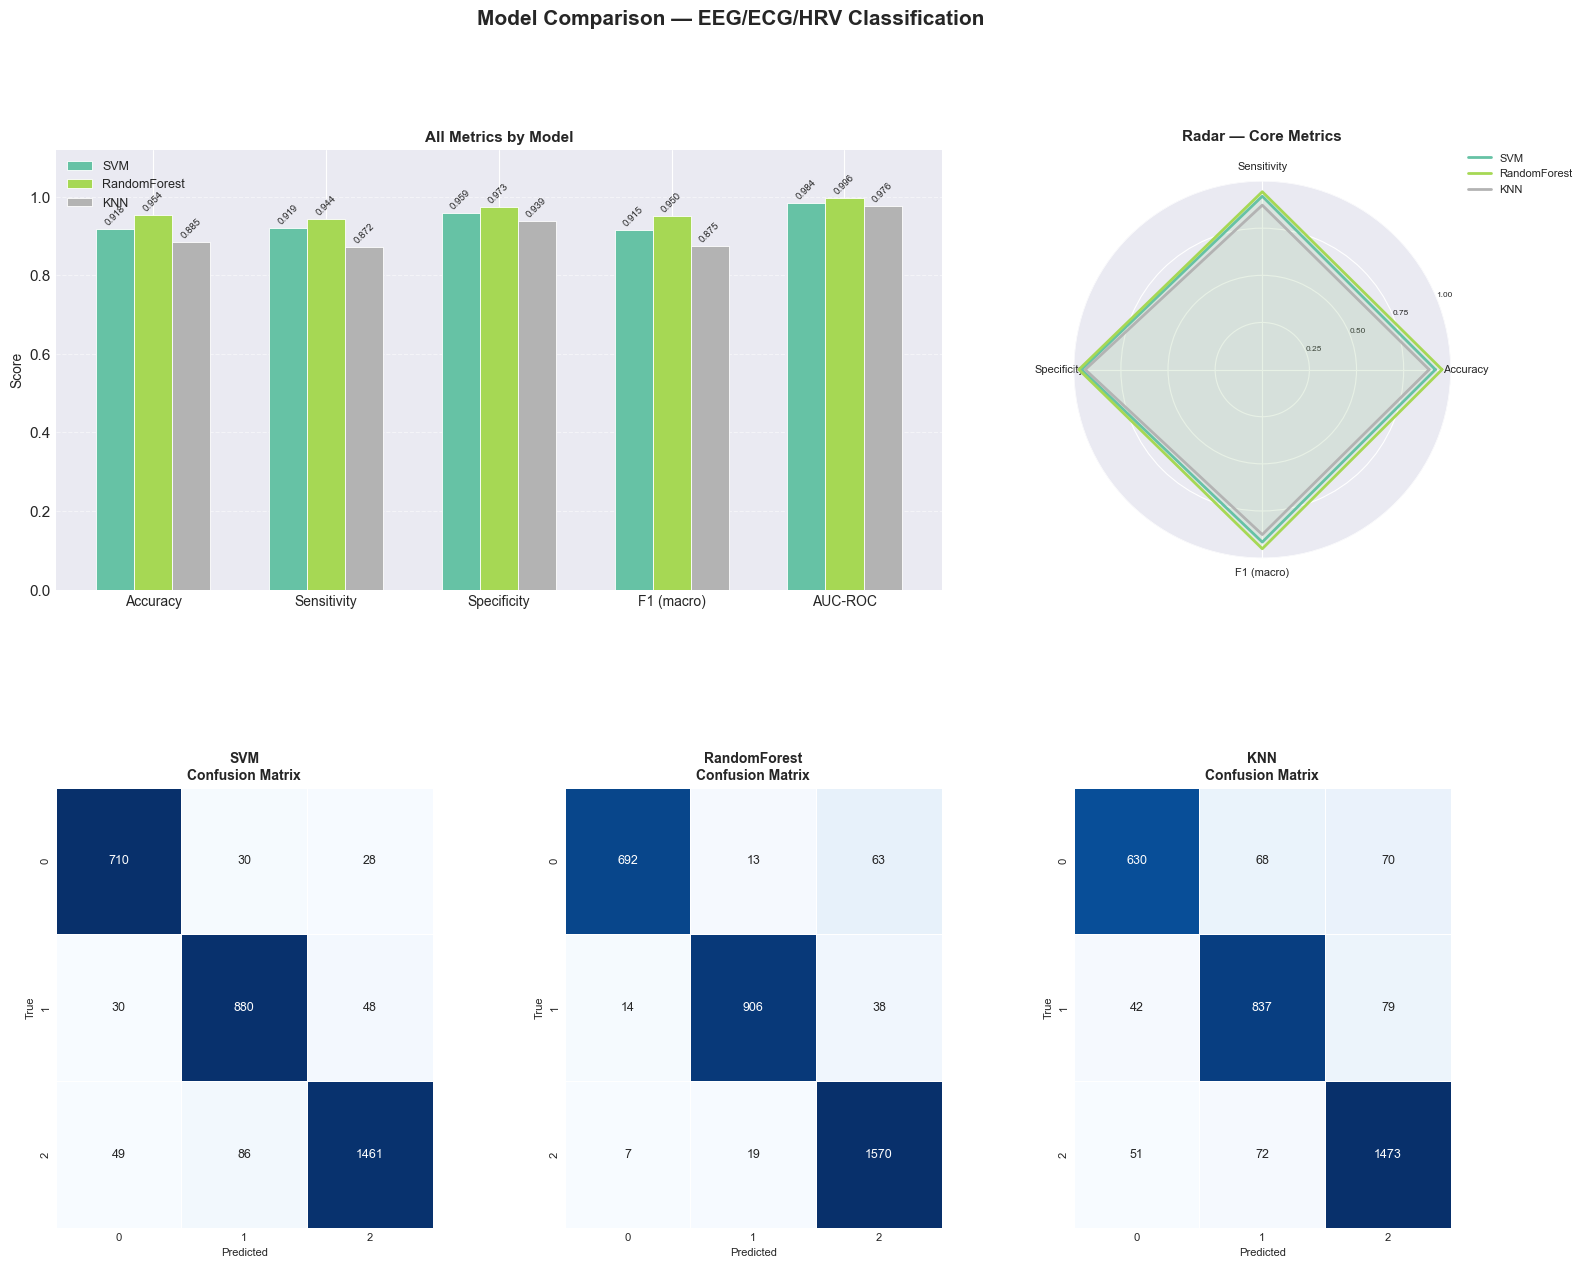

[PLOT] Saved → model_comparison.png


In [30]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import numpy as np
import pandas as pd
# Set style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 11

# Add these for consistent saving
plt.rcParams['savefig.facecolor'] = plt.rcParams['figure.facecolor']  # Use same as display
plt.rcParams['savefig.edgecolor'] = plt.rcParams['figure.edgecolor']
plt.rcParams['savefig.transparent'] = False  # Set to True if you want transparent background

# ── internal plotting ──────────────────────────────────────────

def plot_summary(df: pd.DataFrame, results: list[dict]):
    models  = df.index.tolist()
    metrics = ["Accuracy", "Sensitivity", "Specificity", "F1 (macro)", "AUC-ROC"]
    colors  = plt.cm.Set2(np.linspace(0, 1, len(models)))

    fig = plt.figure(figsize=(18, 14))
    fig.suptitle("Model Comparison — EEG/ECG/HRV Classification",
                 fontsize=15, fontweight="bold", y=0.98)

    gs = gridspec.GridSpec(
        2, 3,
        figure=fig,
        hspace=0.45,
        wspace=0.35,
    )

    # ── 1. Grouped bar chart ───────────────────────────────────
    ax1 = fig.add_subplot(gs[0, :2])
    x      = np.arange(len(metrics))
    width  = 0.22
    offset = np.linspace(-(len(models) - 1) / 2, (len(models) - 1) / 2, len(models))

    for i, (model, color) in enumerate(zip(models, colors)):
        vals = [df.loc[model, m] for m in metrics]
        bars = ax1.bar(x + offset[i] * width, vals, width,
                       label=model, color=color, edgecolor="white", linewidth=0.6)
        for bar, v in zip(bars, vals):
            if not np.isnan(v):
                ax1.text(bar.get_x() + bar.get_width() / 2,
                         bar.get_height() + 0.005,
                         f"{v:.3f}", ha="center", va="bottom",
                         fontsize=7, rotation=45)

    ax1.set_xticks(x)
    ax1.set_xticklabels(metrics, fontsize=10)
    ax1.set_ylim(0, 1.12)
    ax1.set_ylabel("Score", fontsize=10)
    ax1.set_title("All Metrics by Model", fontsize=11, fontweight="bold")
    ax1.legend(fontsize=9)
    ax1.yaxis.grid(True, linestyle="--", alpha=0.5)
    ax1.set_axisbelow(True)

    # ── 2. Radar chart ────────────────────────────────────────
    ax2 = fig.add_subplot(gs[0, 2], polar=True)
    radar_metrics = ["Accuracy", "Sensitivity", "Specificity", "F1 (macro)"]
    N     = len(radar_metrics)
    theta = np.linspace(0, 2 * np.pi, N, endpoint=False)
    theta = np.append(theta, theta[0])

    ax2.set_thetagrids(np.degrees(theta[:-1]), radar_metrics, fontsize=8)
    ax2.set_ylim(0, 1)
    ax2.set_yticks([0.25, 0.5, 0.75, 1.0])
    ax2.set_yticklabels(["0.25", "0.50", "0.75", "1.00"], fontsize=6)
    ax2.set_title("Radar — Core Metrics", fontsize=11,
                  fontweight="bold", pad=15)

    for model, color in zip(models, colors):
        vals = [df.loc[model, m] for m in radar_metrics]
        vals = np.append(vals, vals[0])
        ax2.plot(theta, vals, color=color, linewidth=2, label=model)
        ax2.fill(theta, vals, color=color, alpha=0.08)

    ax2.legend(loc="upper right", bbox_to_anchor=(1.35, 1.1), fontsize=8)

    # ── 3. Confusion matrices ─────────────────────────────────
    n_models = len(results)
    cm_axes  = [fig.add_subplot(gs[1, i]) for i in range(min(n_models, 3))]

    for ax, r, color in zip(cm_axes, results, colors):
        cm = np.array(r["metrics"]["confusion_matrix"])
        n_cls = cm.shape[0]

        # normalise row-wise so colours reflect recall
        cm_norm = cm.astype(float) / (cm.sum(axis=1, keepdims=True) + 1e-10)

        class_labels = [
            str(c) for c in r["metrics"]["per_class_sensitivity"].keys()
        ]

        sns.heatmap(
            cm_norm,
            annot=cm,           # raw counts as annotations
            fmt="d",
            ax=ax,
            cmap="Blues",
            xticklabels=class_labels,
            yticklabels=class_labels,
            linewidths=0.5,
            cbar=False,
            annot_kws={"size": 9},
        )
        ax.set_title(f"{r['model']}\nConfusion Matrix", fontsize=10,
                     fontweight="bold")
        ax.set_xlabel("Predicted", fontsize=8)
        ax.set_ylabel("True",      fontsize=8)
        ax.tick_params(labelsize=8)

    os.makedirs("results/classic_models/", exist_ok=True)
    plt.savefig("results/classic_models/model_comparison.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("[PLOT] Saved → model_comparison.png")


plot_summary(summary_df, results)